# Qwen INT4: две pruning-схемы, одна базовая модель

Цель: проверить обучение двух независимых LoRA-адаптеров с SP-масками **20% и 80%**, скорость относительно двух последовательных обучений и отсутствие взаимного влияния адаптеров.

Основа: `qlora-Qwen3-30B-A3B_torchao_simpruning.ipynb` и эксперимент Llama multiadapter. Загрузка INT4 и TorchAO forward/backward прежние. Используются наши `LocalPruning`, `PruningInstrumentor`, `MultiAdapterPruningTrainer`, PruningLens. Структурного pruning packed INT4-весов здесь нет.


In [1]:
from pathlib import Path
import os, sys, json, subprocess, time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'lora_transfer_pruning').is_dir())
QLORA = ROOT/'experiments/qlora'
PYTHON = ROOT/'.venv/bin/python'
RUN_DIR = QLORA/'slop_experiments/9_torchao_multiadapter/torchao_multiadapter_20261112'
RUN_EXPERIMENT = False  # True: запускает недостающие этапы; готовые результаты не перезаписывает.
CONFIG = dict(steps=40, batch_size=8, context_length=512, train_blocks=512,
              eval_blocks=32, eval_every=10, learning_rate=2e-4, warmup_steps=5, seed=42)
MODES = ['joint', 'joint_prefix', 'prune20', 'prune80']
if RUN_DIR.exists():
    CONFIG = json.loads((RUN_DIR/'config.json').read_text())
print(RUN_DIR)
display(pd.Series(CONFIG, name='configuration').to_frame())


/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/9_torchao_multiadapter/torchao_multiadapter_20261112


,configuration
steps,40.0000
batch_size,8.0000
context_length,512.0000
train_blocks,512.0000
eval_blocks,32.0000
eval_every,10.0000
learning_rate,0.0002
warmup_steps,5.0000
seed,42.0000


## Постановка и честные ограничения

- Один GPTQ checkpoint Qwen3-30B-A3B, его исходные INT4 значения перепакованы для существующего TorchAO matmul; FP16 compute, FP32 LoRA, r=16, alpha=32, dropout=0.
- Адаптеры и SP только в слоях **45–47**: q/k/v/o и gate/up/down всех 128 MoE-экспертов. Вложенные маски, RoPE-пары сохранены; фактические доли немного отличаются от 20/80% из-за целых каналов.
- Одинаковые начальные A/B, сохранённые train/eval blocks, порядок батчей, AdamW, LR schedule, число обновлений **на каждый адаптер**. Каждый run загружает свежую модель в отдельном процессе на **GPU 2**.
- Joint — два последовательных forward/backward с переключением адаптера/маски; один optimizer step обновляет обе независимые группы параметров. Clipping выполняется **отдельно для каждого адаптера**, иначе он связывал бы задачи. Shared GradScaler допустим здесь только при отсутствии overflow/skipped updates — это проверяется.
- `joint_prefix` дополнительно переиспользует выход общих замороженных слоёв 0–44 внутри одной пары проходов. Один временный тензор, не кэш датасета. Это отдельная оптимизация: она неприменима, если задачи отличаются уже в префиксе, есть dropout, обучаемые параметры префикса или разные входы. Eval и сбор traces всегда выполняют полную модель.
- Три проверки не смешиваются: обучение (`before → after`), скорость (`joint vs сумма single`), эквивалентность (`joint/single` одной pruning-схемы). Сходство с исходной непрореженной моделью и точность SP относительно structural TP этим экспериментом **не доказываются**.
- Это короткий эксперимент с одним seed и фиксированным validation subset, не оценка окончательной сходимости или качества на независимом benchmark. Таблицы пилотного прогона приведены ниже. Раздел «Пять повторов на GPU 2» оценивает разброс времени при том же seed и фиксированном датасете.


In [2]:
if RUN_EXPERIMENT:
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    if not (RUN_DIR/'config.json').exists():
        (RUN_DIR/'config.json').write_text(json.dumps(CONFIG, indent=2))
    env = dict(os.environ, CUDA_VISIBLE_DEVICES='2', COMPUTE_DTYPE='fp16',
               CUBLAS_WORKSPACE_CONFIG=':4096:8', TOKENIZERS_PARALLELISM='false')
    timings = {}
    for mode in ['prepare', *MODES]:
        completed = RUN_DIR/'preparation.json' if mode == 'prepare' else RUN_DIR/mode/'result.json'
        if completed.exists():
            print('Using saved:', mode)
            continue
        if mode != 'prepare' and (RUN_DIR/mode).exists():
            raise RuntimeError(f'Incomplete run: {RUN_DIR/mode}; preserve it and select a new run directory or move the failed run aside.')
        command = [str(PYTHON), '-u', str(QLORA / 'slop_experiments/9_torchao_multiadapter/qwen_torchao_multiadapter.py'),
                   '--run-dir', str(RUN_DIR), '--mode', mode]
        started = time.perf_counter()
        with (RUN_DIR/f'{mode}.log').open('w') as log:
            process = subprocess.Popen(command, cwd=ROOT, env=env, stdout=subprocess.PIPE,
                                       stderr=subprocess.STDOUT, text=True)
            try:
                for line in process.stdout:
                    log.write(line); log.flush()
                    if any(word in line for word in ['TRAIN', 'loss', 'CAPTURE', 'PLAN READY', 'DONE', 'Error']):
                        print(line, end='')
                code = process.wait()
            finally:
                if process.poll() is None:
                    process.terminate(); process.wait()
        timings[mode] = time.perf_counter()-started
        (RUN_DIR/'launcher_seconds.json').write_text(json.dumps(timings, indent=2))
        if code:
            raise RuntimeError(f'{mode} failed; see {RUN_DIR / (mode + ".log")}')
    subprocess.run([str(PYTHON), str(QLORA / 'slop_experiments/9_torchao_multiadapter/compare_qwen_multiadapter.py'), str(RUN_DIR)], cwd=ROOT, check=True)


In [3]:
results = {mode: json.loads((RUN_DIR/mode/'result.json').read_text()) for mode in MODES}
preparation = json.loads((RUN_DIR/'preparation.json').read_text())
comparison = json.loads((RUN_DIR/'comparison.json').read_text())
display(pd.DataFrame(preparation['masks']).T[['requested_ratio', 'head_dim', 'head_fraction', 'mlp_fraction', 'layers']])
print('Common one-time mask/data/initialization preparation:', round(preparation['seconds'], 1), 's')
print('Training samples per adapter:', CONFIG['steps']*CONFIG['batch_size'])
print('Input tokens per adapter:', CONFIG['steps']*CONFIG['batch_size']*CONFIG['context_length'])


,requested_ratio,head_dim,head_fraction,mlp_fraction,layers
prune20,0.2,128,0.203125,0.200521,"[45, 46, 47]"
prune80,0.8,128,0.796875,0.799479,"[45, 46, 47]"


Common one-time mask/data/initialization preparation: 157.9 s
Training samples per adapter: 320
Input tokens per adapter: 163840


## Обучилась ли модель?

Eval: один и тот же validation subset, NLL по всем непустым next-token targets, perplexity = exp(NLL), token accuracy. Train loss на разных батчах не обязан монотонно падать. Совпадающие линии специально показаны разными стилями и маркерами.


,run,adapter,phase,loss,perplexity,accuracy
0,joint,prune20,before,2.756762,15.748770,0.488564
1,joint,prune20,after,2.346125,10.445019,0.513821
2,joint,prune80,before,3.770722,43.411395,0.411876
3,joint,prune80,after,3.011903,20.326043,0.458843
4,joint_prefix,prune20,before,2.756762,15.748770,0.488564
5,joint_prefix,prune20,after,2.346125,10.445019,0.513821
6,joint_prefix,prune80,before,3.770722,43.411395,0.411876
7,joint_prefix,prune80,after,3.011903,20.326043,0.458843
8,prune20,prune20,before,2.756762,15.748770,0.488564
9,prune20,prune20,after,2.346125,10.445019,0.513821


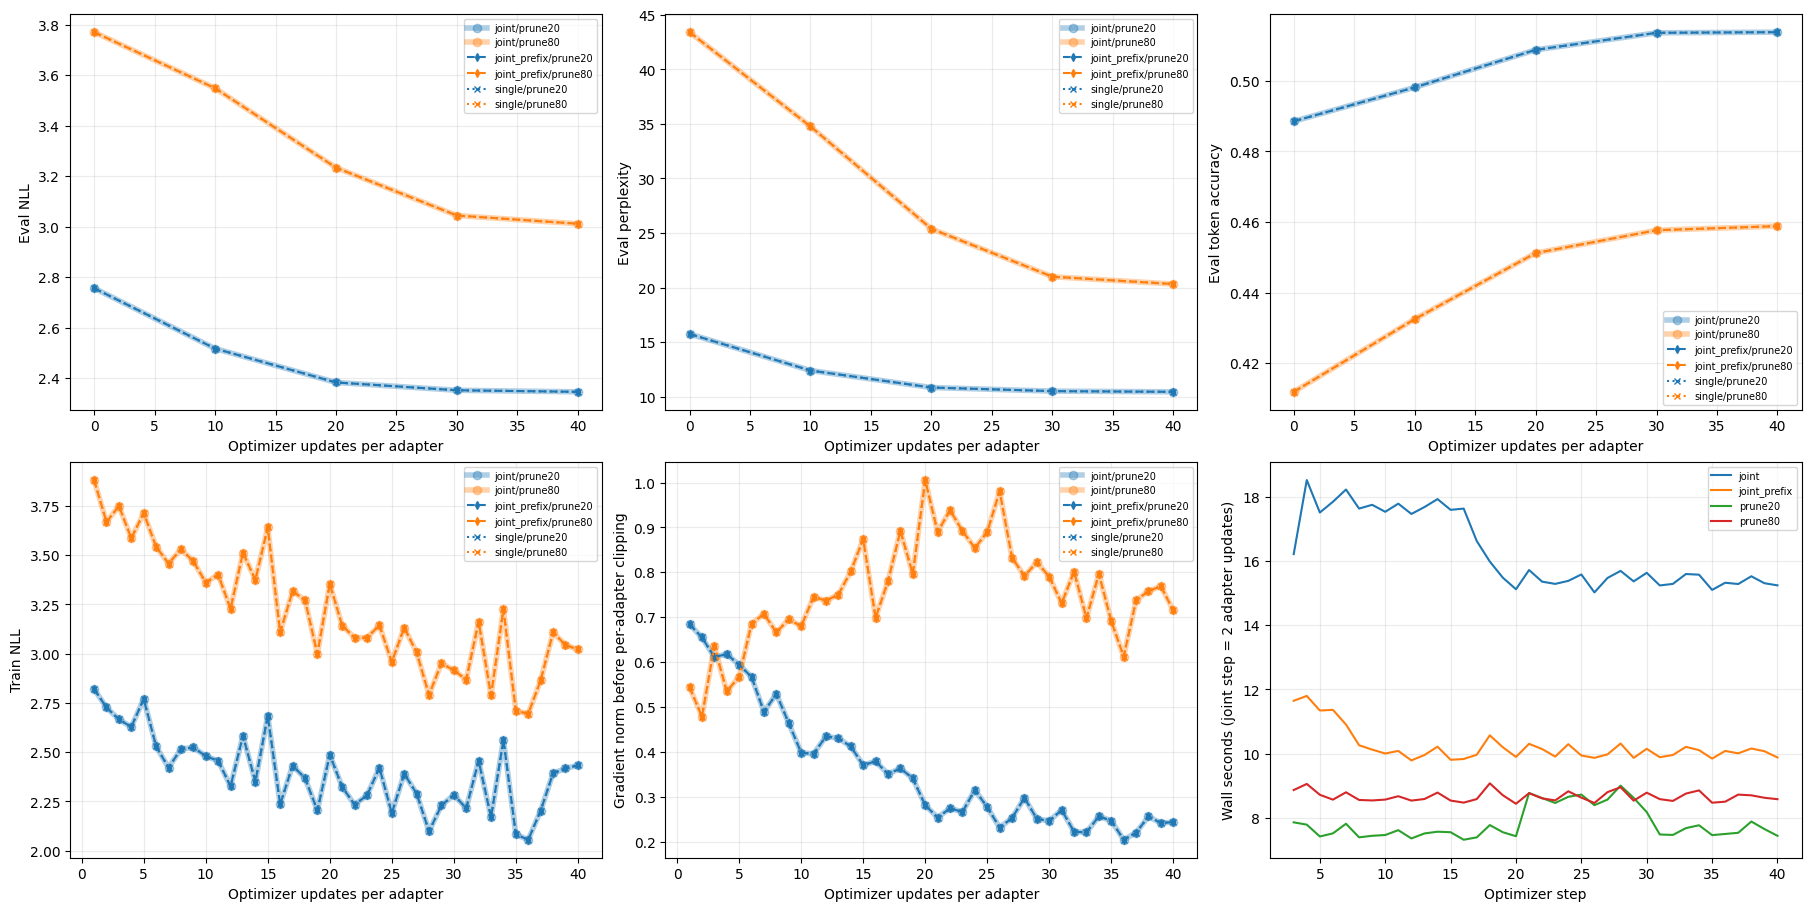

In [4]:
summary = []
for mode, result in results.items():
    for adapter in result['names']:
        for phase in ['before', 'after']:
            summary.append(dict(run=mode, adapter=adapter, phase=phase,
                **{metric: result[phase][f'eval_{adapter}_{metric}'] for metric in ['loss','perplexity','accuracy']}))
metrics = pd.DataFrame(summary)
display(metrics)
metrics.to_csv(RUN_DIR/'metrics_summary.csv', index=False)
fig, axes = plt.subplots(2, 3, figsize=(18, 9), constrained_layout=True)
colors = {'prune20':'tab:blue', 'prune80':'tab:orange'}
styles = {'joint':dict(linestyle='-', linewidth=4, alpha=.35, marker='o', markersize=6),
          'joint_prefix':dict(linestyle='--', linewidth=1.5, marker='d', markersize=4),
          'single':dict(linestyle=':', linewidth=1.5, marker='x', markersize=4)}
for mode,result in results.items():
    kind = mode if mode.startswith('joint') else 'single'
    for adapter in result['names']:
        style = dict(color=colors[adapter], label=f'{kind}/{adapter}', **styles[kind])
        for ax, key, ylabel in zip(axes.flat[:5],
                [f'eval_{adapter}_loss', f'eval_{adapter}_perplexity', f'eval_{adapter}_accuracy',
                 f'adapter_loss_{adapter}', f'adapter_grad_norm_{adapter}'],
                ['Eval NLL','Eval perplexity','Eval token accuracy','Train NLL','Gradient norm before per-adapter clipping']):
            points = [(r['step'],r[key]) for r in result['history'] if key in r]
            assert points, (mode,key)
            ax.plot(*zip(*points), **style)
            ax.set(xlabel='Optimizer updates per adapter', ylabel=ylabel)
    steps = result['steps'][2:]
    axes.flat[5].plot([r['step'] for r in steps], [r['step_seconds'] for r in steps], label=mode)
axes.flat[5].set(xlabel='Optimizer step', ylabel='Wall seconds (joint step = 2 adapter updates)')
for ax in axes.flat:
    ax.legend(fontsize=7); ax.grid(alpha=.25)
fig.savefig(RUN_DIR/'training_dynamics.png', dpi=130)
plt.show()


## Скорость и память

Сравниваем **одинаковую работу: 40 обновлений каждого из двух адаптеров**. `adapter tokens/s` учитывает обработку одного батча каждой задачей (8192 токена на joint step), а не только число уникальных входных токенов (4096).

Steady timings исключают первые два шага и не включают eval/загрузку. Training wall включает scheduled eval. Worker total включает загрузку, установку масок, исходный eval и сохранение/проверки, но не Python imports до старта worker. Общая подготовка планов выполнена один раз для всех вариантов и в сравнительные времена не включается. Serial peak memory — максимум двух запусков, **не сумма**.


,pair_step_s,adapter_tokens_s,train_with_eval_s,worker_total_s,peak_GiB,steady_speedup_vs_serial,worker_speedup_vs_serial
mode,,,,,,,
two separate serial runs,16.500,496.479,936.788,1309.110,27.884,1.000,1.000
joint,16.272,503.451,889.722,1173.967,28.642,1.014,1.115
joint_prefix,10.230,800.789,645.262,931.658,28.654,1.613,1.405


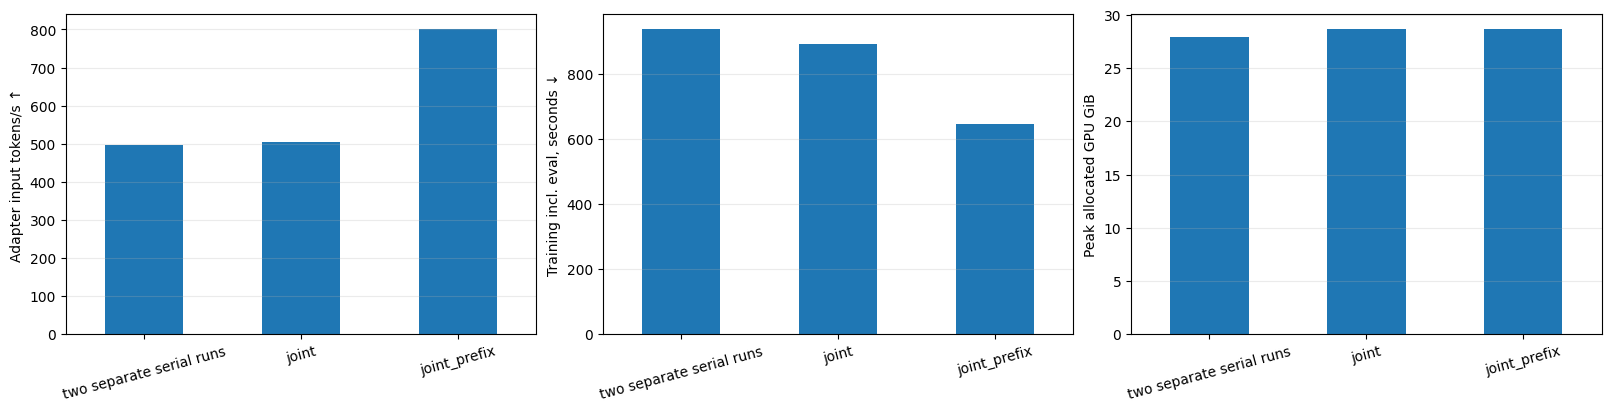

In [5]:
singles = [results['prune20'], results['prune80']]
serial_step = sum(r['steady_pair_or_single_step_seconds'] for r in singles)
serial_wall = sum(r['training_wall_seconds_including_eval'] for r in singles)
serial_total = sum(r['worker_total_seconds'] for r in singles)
rows = [dict(mode='two separate serial runs', pair_step_s=serial_step,
             adapter_tokens_s=2*CONFIG['batch_size']*CONFIG['context_length']/serial_step,
             train_with_eval_s=serial_wall, worker_total_s=serial_total,
             peak_GiB=max(r['peak_GiB'] for r in singles))]
for mode in ['joint', 'joint_prefix']:
    r = results[mode]
    rows.append(dict(mode=mode, pair_step_s=r['steady_pair_or_single_step_seconds'],
                     adapter_tokens_s=r['adapter_tokens_per_second'],
                     train_with_eval_s=r['training_wall_seconds_including_eval'],
                     worker_total_s=r['worker_total_seconds'], peak_GiB=r['peak_GiB']))
speed = pd.DataFrame(rows).set_index('mode')
speed['steady_speedup_vs_serial'] = serial_step/speed.pair_step_s
speed['worker_speedup_vs_serial'] = serial_total/speed.worker_total_s
display(speed.round(3))
speed.to_csv(RUN_DIR/'speed_summary.csv')
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for ax, key, label in zip(axes, ['adapter_tokens_s','train_with_eval_s','peak_GiB'],
                         ['Adapter input tokens/s ↑','Training incl. eval, seconds ↓','Peak allocated GPU GiB']):
    speed[key].plot.bar(ax=ax, rot=15)
    ax.set(ylabel=label, xlabel=''); ax.grid(axis='y', alpha=.25)
plt.show()


## Совпадают ли независимое и совместное обучение?

Проверяются все LoRA A/B тензоры, per-parameter update counts, train loss и нормы градиентов. PruningLens сравнивает реально вызванные внешние LinearBridge hook_in/out в слоях 45–47 на одинаковом probe; неактивные на probe эксперты не покрываются этими traces. Маски всех 387 roots проверяются отдельно, включая синтетические вызовы всех целевых экспертов.

Проверка logits — дополнительно через HF/PEFT путь. Порог `atol=1e-4, rtol=1e-3` используется только для статуса activation comparator; точное равенство весов/logits и абсолютные дельты показываются отдельно. Negative control намеренно изменяет один тензор и обязан дать DIFF. Это контроль независимости задач, **не доказательство отсутствия общей ошибки SP в обоих вариантах**.


In [6]:
checks = pd.read_csv(RUN_DIR/'comparison_checks.csv')
weights = pd.read_csv(RUN_DIR/'comparison_weights.csv')
traces = pd.read_csv(RUN_DIR/'comparison_traces.csv')
logits = pd.read_csv(RUN_DIR/'comparison_logits.csv')
display(checks)
display(weights.groupby(['candidate','adapter']).agg(tensors=('exact','size'), exact_tensors=('exact','sum'),
            worst_max_abs=('max_abs','max'), worst_rel_l2=('rel_l2','max')))
display(traces.groupby(['candidate','adapter','phase','status']).size().rename('hookpoints').to_frame())
display(logits)
print('Negative control:', comparison['negative_control_passed'])
display(pd.DataFrame([dict(mode=mode, frozen_base_unchanged=r['base_versions_unchanged'],
           skipped_updates=sum(step['optimizer_step_skipped'] for step in r['steps']),
           changed_adapter_tensors=r['changed_tensors']) for mode,r in results.items()]))


,candidate,adapter,losses_exact,loss_max_abs,grad_norms_exact,update_counts_exact
0,joint,prune20,True,0.0,True,True
1,joint,prune80,True,0.0,True,True
2,joint_prefix,prune20,True,0.0,True,True
3,joint_prefix,prune80,True,0.0,True,True


tensors  exact_tensors  worst_max_abs  worst_rel_l2
candidate    adapter                                                     
joint        prune20     2328           2328            0.0           0.0
             prune80     2328           2328            0.0           0.0
joint_prefix prune20     2328           2328            0.0           0.0
             prune80     2328           2328            0.0           0.0

hookpoints
candidate    adapter phase  status            
joint        prune20 after  OK            1410
                     before OK            1410
             prune80 after  OK            1392
                     before OK            1410
joint_prefix prune20 after  OK            1410
                     before OK            1410
             prune80 after  OK            1392
                     before OK            1410

,candidate,adapter,phase,exact,max_abs,rel_l2,top1_disagreement
0,joint,prune20,before,True,0.0,0.0,0.0
1,joint,prune20,after,True,0.0,0.0,0.0
2,joint,prune80,before,True,0.0,0.0,0.0
3,joint,prune80,after,True,0.0,0.0,0.0
4,joint_prefix,prune20,before,True,0.0,0.0,0.0
5,joint_prefix,prune20,after,True,0.0,0.0,0.0
6,joint_prefix,prune80,before,True,0.0,0.0,0.0
7,joint_prefix,prune80,after,True,0.0,0.0,0.0


Negative control: True


,mode,frozen_base_unchanged,skipped_updates,changed_adapter_tensors
0,joint,True,0,"{'prune20': 2310, 'prune80': 2304}"
1,joint_prefix,True,0,"{'prune20': 2310, 'prune80': 2304}"
2,prune20,True,0,{'prune20': 2310}
3,prune80,True,0,{'prune80': 2304}


## Итог по критериям

Ячейка ниже выводит фактические результаты, а не заранее заданный успех. Если обычный joint не ускоряет сами шаги, это отдельно видно; выигрыш shared-prefix нельзя приписывать одним лишь маскам.


In [7]:
for mode,r in results.items():
    for name in r['names']:
        before,after = r['before'][f'eval_{name}_loss'],r['after'][f'eval_{name}_loss']
        print(f'{mode}/{name}: eval loss {before:.6f} → {after:.6f}, improved={after<before}')
print('All adapter tensors exactly equal:', comparison['all_adapter_tensors_exact'])
print('All probe logits exactly equal:', comparison['all_logits_exact'])
print('Trace statuses:', comparison['trace_status_counts'])
for mode in ['joint','joint_prefix']:
    print(mode, 'steady speedup:', round(speed.loc[mode,'steady_speedup_vs_serial'],3),
          'worker speedup:', round(speed.loc[mode,'worker_speedup_vs_serial'],3))
print('Artifacts:', RUN_DIR)


joint/prune20: eval loss 2.756762 → 2.346125, improved=True
joint/prune80: eval loss 3.770722 → 3.011903, improved=True
joint_prefix/prune20: eval loss 2.756762 → 2.346125, improved=True
joint_prefix/prune80: eval loss 3.770722 → 3.011903, improved=True
prune20/prune20: eval loss 2.756762 → 2.346125, improved=True
prune80/prune80: eval loss 3.770722 → 3.011903, improved=True
All adapter tensors exactly equal: True
All probe logits exactly equal: True
Trace statuses: {'OK': 11244}
joint steady speedup: 1.014 worker speedup: 1.115
joint_prefix steady speedup: 1.613 worker speedup: 1.405
Artifacts: /glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/9_torchao_multiadapter/torchao_multiadapter_20261112


## Пять повторов на GPU 2

В каждом повторе выполняются 40 обновлений каждого адаптера в трёх режимах. Базовый режим `serial` складывает времена двух отдельных обучений. Все четыре процесса стартуют со свежей моделью и используют один checkpoint, одинаковые батчи, сохранённые pruning-маски и стартовые веса LoRA. Порядок режимов меняется между повторами. Пилотный прогон в выборку из пяти повторов не входит.

Основная метрика — среднее время пары обновлений после двух шагов прогрева, в секундах. Полное время обучения с eval, время worker и пиковая память приведены как дополнительные метрики. Каждый повтор даёт одно наблюдение на режим.

Ускорение — геометрическое среднее отношений времени внутри повторов. В таблице приведены обычные 95% доверительные интервалы и двусторонние p-value парного t-теста для логарифмов отношений. Поправка Холма применяется к трём сравнениям для основной метрики и к шести сравнениям для двух дополнительных метрик. При n=5 вывод t-теста чувствителен к распределению логарифмов отношений. При предположении симметрии парных логарифмов относительно нуля проверка со сменой знаков даёт 32 комбинации, поэтому минимальное двустороннее p-value равно 0,0625. Выводы относятся к времени этой конфигурации на указанной GPU.


Повторов с завершённой проверкой эквивалентности: 5/5


,run,mode,pair_step_s,train_with_eval_s,worker_total_s,adapter_tokens_s,peak_GiB
0,run_01,serial,15.748,894.194,1259.012,520.204,27.884
1,run_01,joint,15.984,879.431,1155.270,512.499,28.642
2,run_01,joint_prefix,10.164,645.153,932.879,805.961,28.654
3,run_02,serial,15.792,896.725,1263.906,518.734,27.884
4,run_02,joint,15.797,868.463,1137.420,518.576,28.642
5,run_02,joint_prefix,10.013,632.890,900.218,818.154,28.654
6,run_03,serial,15.306,870.803,1229.619,535.210,27.884
7,run_03,joint,15.488,852.237,1122.229,528.927,28.642
8,run_03,joint_prefix,10.344,654.788,928.328,791.981,28.654
9,run_04,serial,16.599,946.240,1330.583,493.537,27.884


mean                             sd                     
mode                  joint joint_prefix    serial   joint joint_prefix  serial
metric                                                                         
adapter_tokens_s    511.097      806.405   511.512  26.666       23.500  19.239
pair_step_s          16.065       10.166    16.033   0.890        0.295   0.605
peak_GiB             28.642       28.654    27.884   0.000        0.000   0.000
train_with_eval_s   883.973      643.079   911.874  49.194       16.985  35.260
worker_total_s     1159.751      916.745  1281.687  57.396       21.423  44.260

,metric,reference,candidate,n,speedup,ci95_low,ci95_high,paired_t_p,sign_flip_p,paired_t_p_holm
0,pair_step_s,serial,joint,5,0.99862,0.94417,1.05622,0.94891,0.9375,0.94891
1,pair_step_s,serial,joint_prefix,5,1.57687,1.48221,1.67758,0.00003,0.0625,0.00007
2,pair_step_s,joint,joint_prefix,5,1.57905,1.50458,1.65720,0.00001,0.0625,0.00004
3,train_with_eval_s,serial,joint,5,1.03218,0.97475,1.09299,0.19935,0.1875,0.19935
4,train_with_eval_s,serial,joint_prefix,5,1.41753,1.33142,1.50922,0.00010,0.0625,0.00050
5,train_with_eval_s,joint,joint_prefix,5,1.37334,1.30408,1.44628,0.00007,0.0625,0.00042
6,worker_total_s,serial,joint,5,1.10566,1.04807,1.16641,0.00646,0.0625,0.01291
7,worker_total_s,serial,joint_prefix,5,1.39773,1.31675,1.48368,0.00010,0.0625,0.00050
8,worker_total_s,joint,joint_prefix,5,1.26416,1.20232,1.32918,0.00020,0.0625,0.00061


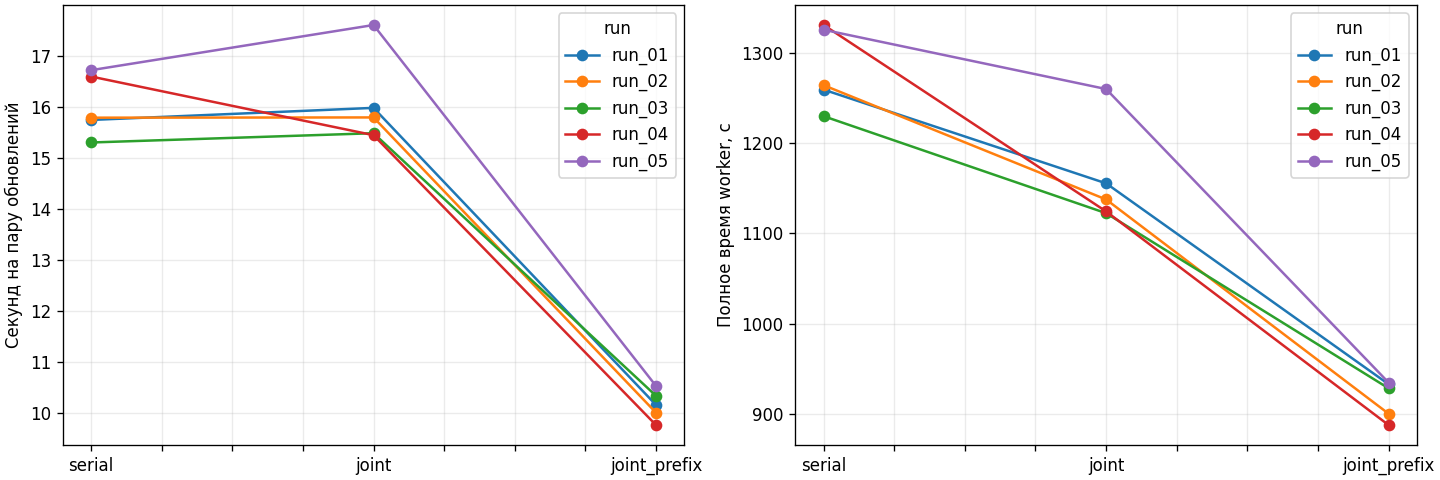

In [8]:
REPEATS_DIR = QLORA / 'slop_experiments/9_torchao_multiadapter/torchao_multiadapter_20261118_gpu2'
RUN_REPEATS = False

if RUN_REPEATS:
    subprocess.run([str(PYTHON), '-u', str(QLORA / 'slop_experiments/9_torchao_multiadapter/repeat_qwen_multiadapter.py'),
                    '--output', str(REPEATS_DIR), '--prepared-dir', str(RUN_DIR)],
                   cwd=ROOT, check=True)

completed = sorted(REPEATS_DIR.glob('run_*/comparison.json'))
print(f'Повторов с завершённой проверкой эквивалентности: {len(completed)}/5')
if (REPEATS_DIR / 'paired_comparisons.csv').is_file():
    repeat_timings = pd.read_csv(REPEATS_DIR / 'timings.csv')
    repeat_summary = pd.read_csv(REPEATS_DIR / 'timing_summary.csv')
    repeat_comparisons = pd.read_csv(REPEATS_DIR / 'paired_comparisons.csv')
    display(repeat_timings.round(3))
    display(repeat_summary.pivot(index='metric', columns='mode', values=['mean', 'sd']).round(3))
    display(repeat_comparisons.round(5))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for ax, metric, label in zip(axes, ('pair_step_s', 'worker_total_s'),
                                 ('Секунд на пару обновлений', 'Полное время worker, с')):
        times = repeat_timings.pivot(index='mode', columns='run', values=metric)
        times.reindex(['serial', 'joint', 'joint_prefix']).plot(ax=ax, marker='o')
        ax.set(xlabel='', ylabel=label)
        ax.grid(alpha=0.25)
    plt.show()
